# Prot2Motif inference example

This notebook runs inference directly in the current Python process and visualizes predictions for `example/sequence_example.fasta`. It explicitly loads `prot2motif.pt` from the project root.

Install dependencies with `python -m pip install -r requirements.txt`, then launch Jupyter from the `prot2motif` project root: `jupyter lab example/inference_example.ipynb`.

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
from pathlib import Path

import joblib
import logomaker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import sys
sys.path.append('../')

from inference.run_generate import (
    classify_batch,
    generate_motifs_batch,
    load_model,
    load_sequences,
)
from inference.tokenizer import AminoAcidTokenizer

MODEL_PATH = "../model/best_model_E_epoch_1.pt"
CLASSIFIER_PATH = "../model/classifier_LogisticRegression_decoder.pkl"
FASTA_PATH = "./sequence_example.fasta"

records = load_sequences(FASTA_PATH)
if not records:
    raise ValueError(f"No protein sequences found in {FASTA_PATH}")

protein_ids = [protein_id for protein_id, _ in records]
sequences = [sequence for _, sequence in records]
print(f"Loaded {len(records)} protein sequence(s) from {FASTA_PATH}.")

Loaded 1 protein sequence(s) from ./sequence_example.fasta.


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model(MODEL_PATH, device)
classifier = joblib.load(CLASSIFIER_PATH)
tokenizer = AminoAcidTokenizer()
tokens = tokenizer.batch_encode(sequences, max_len=1024, padding=True)

thresh = 0.25

probabilities = classify_batch(model, tokens, classifier, device)
positive_mask = probabilities >= thresh
positive_motifs = (
    generate_motifs_batch(model, tokens[positive_mask], device)
    if positive_mask.any()
    else np.empty((0, 26, 5), dtype=np.float16)
)

print(f"Device: {device}")
print(f"Positive predictions (probability >= {thresh}): {int(positive_mask.sum())} of {len(records)}")

Device: cpu
Positive predictions (probability >= 0.25): 1 of 1


In [4]:
def draw_logo_on_ax(ax, motif, length_motif):

    motif_df = pd.DataFrame(motif[:length_motif, :4], columns=['A', 'C', 'G', 'T'])
    pwm = motif_df.div(motif_df.sum(axis=1), axis=0).fillna(0)
    entropy = -np.nansum(pwm * np.log2(pwm.replace(0, np.nan)), axis=1)

    R = np.log2(4) - entropy
    info_motif = pwm.mul(R, axis=0)

    logo = logomaker.Logo(
        info_motif,
        ax=ax,
        font_name='sans',
        color_scheme={'A': 'blue', 'C': 'yellow', 'G': 'green', 'T': 'red'},
        vpad=0,
        width=1.0
    )
    ax.set_ylabel('bits', fontsize=12)
    ax.set_ylim(0, 2)
    ax.set_xlim(-0.5, length_motif - 0.5)
    for spine in ax.spines.values():
        spine.set_visible(True)

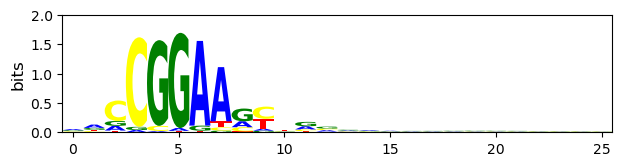

In [5]:
fig = plt.figure(figsize=(8, 8))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 4], hspace=0.1)

gs_top = gs[0].subgridspec(1, 2, width_ratios=[1, 0.1], wspace=0.05)
ax_logo = fig.add_subplot(gs_top[0])
draw_logo_on_ax(ax_logo, positive_motifs[0], 26)